In [1]:
import sys
import os
# Path to the folder of the stand-alone model on your machine
path = r'/Users/MuhammadAwais/Reps/MESSAGEix-CA/'
file = 'MESSAGE_CA__test__v4.xlsx'
# Path to subfolder for the stand-alone model data (Excel files)
os.chdir(path)
print(os.getcwd())
sys.path.insert(1, path)


/Users/MuhammadAwais/Reps/MESSAGEix-CA


In [2]:
import message_ix
import ixmp as ix
from ixmp import Scenario


# Stand-alone model
modelName = 'MESSAGEix_CA'      # A MESSAGE model name
scenarioName = 'baseline'       # A MESSAGE model scenario name

mp = ix.Platform()
# mp2 = ix.Platform(dbtype='HSQLDB')

# Notic: either choose I or II
# I) Creating a new MESSAGE stand-alone model
msg = message_ix.Scenario(mp, modelName, scenarioName,
                            version='new', annotation='')


UnboundLocalError: local variable 'msg' referenced before assignment

In [3]:
ssp = 'SSP1'

In [4]:
scenarios = [   'CD_Links_SSP2_R14|INDC2030i_forever-con-prim-dir-ncr',
                'CD_Links_SSP2_R14|NPi2020_1000-con-prim-dir-ncr']
# for scenario in scenarios:
scenario = scenarios[0]

# Model and scenarios to clone
modelName = scenario.split('|')[0]
scenarioName = scenario.split('|')[1]

# Loading platform
mp1 = ix.Platform(name = 'ene_ixmp')

# Importing the global model scenario used as basis
msgWSC = message_ix.Scenario(mp1, modelName, scenarioName)


Existing index sets of 'map_tec_storage' ['technology', 'storage_tec'] do not match ['node', 'technology', 'storage_tec', 'level', 'commodity']
This Scenario has a solution, use `Scenario.remove_solution()` or `Scenario.clone(..., keep_solution=False)`


In [5]:

msg.read_excel(path = path + file, init_items = True,
              commit_steps=False)

Cannot read set 'is_relation_lower_time': index set(s) cannot be inferred for name(s) ['node_rel', 'year_rel']
Cannot read set 'is_relation_upper_time': index set(s) cannot be inferred for name(s) ['node_rel', 'year_rel']


In [6]:
from demands import demands
import pandas as pd
import numpy as np
from itertools import product
from downscale_demands import downscale_demands

In [7]:

nodeName = 'Canada'     # Name of the stand-alone model region.
regionName = 'R14_NAM'      # Name of the reference region in MESSAGE global
ieaName = "'Canada'"         # In the form of: "'Russian Federation'"
plattsName = 'Canada'        # In the form of: 'Russia'
suffix = '_CAN'             # The extension of Excel files, like: '_RU'
iso = 'CAN'
reg = regionName


# region to country mapping
reg_df = pd.read_excel( str(path) +
                       str('/') + str('iso_reg.xlsx'), 'Sheet1')
reg_df['node'] = str('R14_') + reg_df['node'].astype(str)
isoreg = reg_df[reg_df['node']==reg]
isoreg = isoreg['iso'].tolist()

# country and region name mapping
country_map = pd.read_excel( str(path) + str('/') + str(nodeName) +
                            str('_map.xlsx'), 'country_map')
country = country_map.loc[(country_map['include']=='Y')&
                          (country_map['msg_14'] == reg.split('_')[1])]
#    iea = country.loc[country.iso==iso].iea[0]

# SSP GDP data
ssp_gdp_df = pd.read_excel(
        str(path) + str('/') + str('OECD_SSP_GDP_PPP.xlsx'),
        'OECD_SSP_GDP_PPP',
        header = 0 )


ssp_gdp_df = ssp_gdp_df.loc[ ( ssp_gdp_df.Scenario == ssp+ '_v9_130325' )&
                            ( ssp_gdp_df.Region == iso ) ].reset_index(
                                drop=True)

# SSP population data
ssp_pop_df = pd.read_excel(
        str(path) + str('/') + str('OECD_SSP_POP.xlsx'),
        'OECD_SSP_POP',
        header = 0 )

ssp_pop_df = ssp_pop_df.loc[ ( ssp_pop_df.Scenario == ssp + '_v9_130325' )&(
    ssp_pop_df.Region == iso  ) ].reset_index(drop=True)

# SSP data scaling to account for changes since release
wbi_2015_df = pd.read_excel( str(path) + str('/') + str('wbi_pop_gdp_2015.xlsx'), 'wbi_pop_gdp_2015')
wbi_2015_df = wbi_2015_df.loc[(wbi_2015_df.iso == iso)].reset_index(drop=True)
for aaa in ssp_pop_df.index:
    if not (wbi_2015_df.loc[wbi_2015_df['iso']==ssp_pop_df.Region[aaa]]).empty:
        x0 = [ 1e-6*wbi_2015_df.loc[wbi_2015_df['iso']==ssp_pop_df.Region[aaa]].pop_2015.to_numpy()[0] ]
        x = ssp_pop_df.iloc[aaa,range(12,len(ssp_pop_df.columns))]
        dx = x.diff()/ssp_pop_df.iloc[aaa,range(12,len(ssp_pop_df.columns))]
        dx = dx.replace([np.inf,-np.inf,np.nan],0)
        xf = []
        xfi = x0[0]
        for ggg in dx.index:
            rs = xfi*(1+dx[ggg])
            xf.append(round(rs*1e6)/1e6)
            xfi = rs
        ssp_pop_df.iloc[aaa,range(12,len(ssp_pop_df.columns))] = xf


for aaa in ssp_gdp_df.index:
    if not (wbi_2015_df.loc[wbi_2015_df['iso']==ssp_gdp_df.Region[aaa]]).empty:
        x0 = [ 1e-9*wbi_2015_df.loc[wbi_2015_df['iso']==ssp_gdp_df.Region[aaa]].gdp_ppp_usd_2015.to_numpy()[0] ]
        x = ssp_gdp_df.iloc[aaa,range(12,len(ssp_gdp_df.columns))]
        dx = x.diff()/ssp_gdp_df.iloc[aaa,range(12,len(ssp_gdp_df.columns))]
        dx = dx.replace([np.inf,-np.inf,np.nan],0)
        xf = []
        xfi = x0[0]
        for ggg in dx.index:
            rs = xfi*(1+dx[ggg])
            xf.append(round(rs*1e9)/1e9)
            xfi = rs
        ssp_gdp_df.iloc[aaa,range(12,len(ssp_gdp_df.columns))] = xf

    

In [8]:
ssp_pop_df

,Model,Scenario,Region,UN_Code,Country_Name,Status,Eleven_region,Variable,Unit,2000,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
0,OECD Env-Growth,SSP1_v9_130325,CAN,124.0,Canada,IND,NAM,Population,million,30.667,...,49.640492,51.155173,52.494963,53.570416,54.382498,54.925636,55.04954,54.756598,54.122573,53.238233


In [9]:

# Get the time parameters
first_year = msg.set('cat_year').loc[msg.set(
        'cat_year')['type_year'] == 'firstmodelyear', 'year'].item()
msg_yrs = [int(x) for x in msg.set('year')]
hist_year = 2015
demand_yrs = [x for x in msg_yrs if x >= hist_year]

df_region = msgWSC.par('demand',{'node': reg,'year':demand_yrs})
df_dem = df_region
cmdtys = df_dem['commodity'].unique().tolist()

# Get the historical demands for country in the region from excel sheet
# xls_par = pd.ExcelFile(path + '/Parameters'+suffix+'.xlsx')
hist_act_df = msg.par('historical_activity').dropna(axis =1)




In [10]:
df_d = msg.par('demand')
cmdtys = df_d['commodity'].unique().tolist()

In [12]:
country.iso.values

array(['CAN'], dtype=object)

In [13]:
# GDP and population
ssp_df = []
for ccc in country.iso.values.tolist():

    c_ssp_gdp_df = ssp_gdp_df.loc[ ssp_gdp_df.Region == ccc ]
    c_ssp_pop_df = ssp_pop_df.loc[ ssp_pop_df.Region == ccc ]
    gdp = []
    pop = []
    gdpc = []

    for jjj in demand_yrs:

        if jjj < 2110:
            mmm = jjj
        else:
            mmm = 2100

        gdp.append(c_ssp_gdp_df[mmm].values[0])
        pop.append(c_ssp_pop_df[mmm].values[0])
        gdpc.append(1e3*c_ssp_gdp_df[mmm].values[0]/c_ssp_pop_df[mmm].values[0])

    ssp_df.append(pd.DataFrame({
        'year':demand_yrs,
        'gdp':gdp,
        'pop':pop,
        'gdpc':gdpc,
        'iso':ccc}))

ssp_df = pd.concat(ssp_df)




In [14]:
cmdtys

['i_feed', 'i_spec', 'i_therm', 'rc_spec', 'rc_therm', 'transport']

In [63]:

# initial df for demand data
dmds = []

# Go through each demand commodity and update demands then add to df above
for cmdty in cmdtys:

    # Isolate regional demands
    dff = df_region[df_region['commodity']==cmdty].sort_values('year').reset_index(drop=True)

    # use dff as basis for country df so update node location
    dff['node'] = iso
    dff['node'] = dff['node'].str.replace('PAK','Pakistan')

    # Add percent change
  # dff['pc'] = dff['value'].diff()
    dff['pc'] = dff['value'].pct_change(periods = 1)
  #  for iii in dff.index:
  #       if iii == 0:
  #            dff.pc[iii] = 0
  #    else:
  #           dff.pc[iii] = ( dff.pc[iii] / dff.value[(iii-1)] ) -1

    dff = dff.replace([np.inf,-np.inf,np.nan],0)

    # list of technologies outputing on the demand level
    tec_list = list(set((msg.par(
                    'output', {'level': dff.level.values[0],
                               'commodity': cmdty}))['technology']))

    # filter historical activity datafrme to include technologies for current commodity
    if(len(tec_list)>1):
        ha = hist_act_df.loc[hist_act_df.technology.isin(tec_list)]
    else:
        ha = hist_act_df.loc[hist_act_df['technology'] == tec_list[0]]

    # output efficiency for tecs (typically = 1)
    oe = msg.par('output', {
                        'technology': ha.technology.unique(),
                        'commodity': cmdty}).groupby(['year_act','technology']).mean().reset_index()
    oe = oe[['technology','year_act','value']]

    # update historical activity to account for efficiency losses at the output
    ha = pd.merge( ha, oe, on = ['year_act','technology'], how = 'left' ).dropna()
    ha['value'] = ha['value_x'] * ha['value_y']

    # Go through each demand year and scale the historical demands to follow regional growth pattern
    # must be sorted by year because the state equations are updated sequentially
    for ind in dff.index:

        # if the first year, use the historical demands calibrated to iea db
        if dff.year.iloc[ind] == demand_yrs[0]:

            # isolate the regonal demand target
            # dt = dff.value.iloc[ind]

            # sum iea demands
            dm = ha.loc[ha['year_act']==dff.year.iloc[ind]].groupby('node_loc').sum().reset_index()
            dm = dm[['node_loc','value']]

            # isolate gdp information
            gdp = []
            gdpc = []


            gdp.append(ssp_df.gdp.to_numpy()[0])
            gdpc.append(ssp_df.gdpc.to_numpy()[0])

            dm = pd.DataFrame({'node':dm.node_loc.to_numpy(),
                                'value':dm.value.to_numpy(),
                                'ei':dm.value.to_numpy()/gdp,
                                'gdp':gdp,
                                'gdpc':gdpc})

            dt = dm.value
            dm0 = dm


        # downscale the demands to match growth rate from regional pathway
        else:

            # update total regional demands using growth rate from global model
            dt = dm.value * (1 + dff.pc.iloc[ind])

            # update state equation variables
            dm0 = dm
            gdpf = []
            gdpcf = []

            inds = (ssp_df['year']==dff.year.iloc[ind])
            gdpf.append(ssp_df.loc[inds,'gdp'].to_numpy()[0])
            gdpcf.append(ssp_df.loc[inds,'gdpc'].to_numpy()[0])

            # unload some variables and call LP downscaling algorithm
            names = dm0.node.to_numpy()
            vl = dm0.value.to_numpy()
            gdpco = dm0.gdpc.to_numpy()

            # don't allow 0 intensities in future time steps if not biomass technologies
            if not 'biomass' in cmdty:
                ei = vl / gdpco
               # ei[np.where(ei==0)] = min(ei[ei.nonzero()])
                vl = ei * gdpco

            dmf = downscale_demands(
                dt, # target
                vl, # initial country demands
                gdpco, # initial country income
                gdpcf, # final country income
                gdpf, # final country total GDP
                names) # node names

            # update demand state variables
            dm = pd.DataFrame({'node':dmf.node.to_numpy(),
                                'value':dmf.value.to_numpy(),
                                'ei':dmf.value.to_numpy()/gdpf,
                                'gdp':gdpf,
                                'gdpc':gdpcf})

#         # Check
#         print('--- cmdty ---')
#         print(cmdty)

#         print('--- dm ---')
#         print(dm)

#         print('--- country: total ---')
#         print(dff.value.iloc[ind])

#         print('---country: pc set----')
#         print(dff.pc.iloc[ind])

#         print('---country: pc act----')
#         print(dm.value.sum()/dm0.value.sum()-1)

#         print('--- target ---')
#         print(dt)

#         print('---  total ---')
#         print(dm.value.sum())

        # set the country level demand for this commodity and time step
        dff.value.iloc[ind] = dm.value.to_numpy()[0]

#         if ind > 0 :
#             print('--- diff ---')
#             print(((dff.value.iloc[ind]/dff.value.iloc[ind-1])-1))
#             print(dff.pc.iloc[ind])

    # add demand for particular commodity to the model
    dmds.append(dff[list(msg.par('demand').columns)])

dmds = pd.concat(dmds).reset_index()

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.1217536083179     1.0                 1.0                 -                1.0                 1.0                 
0.01277888740458    0.1049569501974     0.1049569501974     0.9046526990989  0.1049569501974     0.1334744075502     
0.0006601325423435  0.00542187251338    0.00542187251338    0.9632335063813  0.00542187251338    0.08583260803841    
1.250691268625e-07  1.027231377491e-06  1.02723137746e-06   1.0              1.02723137746e-06   0.08609310921496    
6.253383870632e-12  5.136169688599e-11  5.136159553221e-11  0.9999499999794  5.136157364633e-11  0.08609280209086    
Optimization terminated successfully.
         Current function value: 0.086093    
         Iterations: 4
Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.05937720803129    1.0                 1.0                 -        

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.1628349912037     1.0                 1.0                 -                1.0                 1.0                 
0.01676710380136    0.1029699063906     0.1029699063906     0.9063151531499  0.1029699063906     0.1435220182393     
0.001165807536832   0.007159441150912   0.007159441150912   0.9474568250082  0.007159441150912   0.1239723323541     
6.46397982059e-08   3.969649974018e-07  3.969649974844e-07  0.9999450422674  3.969649968227e-07  0.1151421619131     
3.230897124572e-12  1.984822609354e-11  1.984833131186e-11  0.9999499998006  1.984824996537e-11  0.1151417265164     
Optimization terminated successfully.
         Current function value: 0.115142    
         Iterations: 4
Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.004165157315693   1.0                 1.0                 -        

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

1.439121492736e-05  0.0002006042406971  0.0002006042406957  1.0              0.0002006042406957  0.05080721728378    
7.239551093438e-10  1.009146590814e-08  1.009146570474e-08  0.9999496959655  1.009146572418e-08  0.05072737461282    
3.619065245916e-14  5.046344818512e-13  5.045616702226e-13  0.9999500011658  5.045732848264e-13  0.05072737061477    
Optimization terminated successfully.
         Current function value: 0.050727    
         Iterations: 5
Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.07001250524848    1.0                 1.0                 -                1.0                 1.0                 
0.007479132860146   0.1068256711226     0.1068256711226     0.90306133342    0.1068256711226     0.1249876528374     
0.001439641861796   0.02056263886982    0.02056263886982    0.8148542651346  0.02056263886982    0.04896913765134    
1.487992840581e-05  0.0002125324376408  0.0002125324376408  1.0     

... (5 outputs left out)


8.648743813403e-10  1.441523813262e-08  1.441523814899e-08  0.9999488943517  1.44152381513e-08   0.04242445613785    
4.325605168913e-14  7.207529867868e-13  7.207498486927e-13  0.999950000883   7.207619062864e-13  0.04242445006479    
Optimization terminated successfully.
         Current function value: 0.042424    
         Iterations: 5
Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.06675572618855    1.0                 1.0                 -                1.0                 1.0                 
0.007137099452029   0.10691366658       0.10691366658       0.9029858242148  0.10691366658       0.1246076662538     
0.001380457921745   0.02067924357299    0.02067924357299    0.8134944231264  0.02067924357299    0.04669024119064    
1.570271876236e-05  0.0002352265439808  0.000235226543982   1.0              0.0002352265439821  0.04730022540513    
7.92429353615e-10   1.18705829412e-08   1.187058292634e-08  0.99994

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.1175802666802     1.0                 1.0                 -                1.0                 1.0                 
0.012362070659      0.1051372905338     0.1051372905338     0.9045002063393  0.1051372905338     0.1326182627473     
0.0008965809689704  0.007625267353823   0.007625267353823   0.9416703008834  0.007625267353823   0.0827894050488     
4.599354430207e-07  3.91167205196e-06   3.911672052104e-06  1.0              3.911672052112e-06  0.08314298613356    
2.299684985001e-11  1.955840549281e-10  1.955838963008e-10  0.9999499999254  1.95583885068e-10   0.08314180396242    
Optimization terminated successfully.
         Current function value: 0.083142    
         Iterations: 4
Primal Feasibility  Dual Feasibility    Duality Gap         Step             Path Parameter      Objective          
0.1068945635711     1.0                 1.0                 -        

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)
/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

In [16]:
 dmds['node'] = dmds['node'].str.replace('CAN','Canada')

In [17]:
msg.add_par('demand',dmds)

In [18]:
msg.commit('demands updated')

In [4]:
growth = msg.par('growth_activity_up')
growth.head()

,node_loc,technology,year_act,time,value,unit
0,Canada,LNG_exp,2010,year,0.06,%
1,Canada,LNG_exp,2020,year,0.06,%
2,Canada,LNG_exp,2030,year,0.06,%
3,Canada,LNG_exp,2040,year,0.06,%
4,Canada,LNG_exp,2050,year,0.06,%


In [6]:
#  msg.check_out()

In [7]:
# demand = msg.par('demand',{'commodity':'rc_therm'})
# demand.head()

In [8]:
# msg.remove_par('demand', demand)

In [9]:
# demand['value'] = demand['value'] * 0.75

In [10]:
# msg.add_par('demand',demand)

In [21]:
msg.check_out()

In [11]:

# growth_gas = growth[growth['technology'].str.contains('gas')]
# msg.remove_par('growth_activity_up', growth_gas)
# growth_gas['value'] = growth_gas['value'] * 0.5
# msg.add_par('growth_activity_up', growth_gas)

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package so we can avoid doing imports until


In [22]:
growth_gas_lo = msg.par('growth_activity_lo')
growth_gas_lo = growth_gas_lo[growth_gas_lo['technology'].str.contains('gas')]
msg.remove_par('growth_activity_lo', growth_gas_lo)
growth_gas_lo['value'] = growth_gas_lo['value'] * 3
msg.add_par('growth_activity_lo', growth_gas_lo)

In [23]:
# #msg.check_out()

# resource_1 = msg.par('resource_volume',{'commodity':'gas_1'})
# resource_2 = msg.par('resource_volume',{'commodity':'gas_2'})
# resource_3 = msg.par('resource_volume',{'commodity':'gas_3'})
# resource_4 = msg.par('resource_volume',{'commodity':'gas_4'})

In [24]:
# frames = [resource_1, resource_2, resource_3, resource_4]
# import pandas as pd
# resource = pd.concat(frames)

In [25]:
# resource

In [26]:
# #resource['value'] = resource['value'] *2.5 
# msg.add_par('resource_volume', resource)


In [27]:
msg.model

'MESSAGEix_CA'

In [28]:
msg.version

14

In [29]:
msg.commit('')

In [30]:

# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)

# Solving the model
msg.solve(model='MESSAGE', case=caseName)


In [85]:
nodeloc = 'Canada'
from postprocess import plotdf_sec, plotdf, group, multiply_df
yr = msg.set('cat_year', {'type_year': 'firstmodelyear'}).year.item()

Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 
msg = msg.clone(keep_solution=False)

In [86]:
# A function for making model output ready
def model_output(msgBAS, tecs, nodeloc, parname, coms=None):
    df1 = msg.var('ACT', {'technology': tecs, 'node_loc': nodeloc})
    df2 = msg.par(parname, {'technology': tecs, 'node_loc': nodeloc})
    if coms:
        if isinstance(coms, str):
            coms = [coms]
        df2 = df2.loc[df2['commodity'].isin(coms)]
    df = multiply_df(df1, 'lvl', df2, 'value')
    return df, df2


In [134]:

tecs = list(set(msg.par('output', {'level': 'primary'}).technology))
tecs_imp = list(['coal_imp', 'oil_imp', 'gas_imp', 'u5_imp', 'meth_imp',
                 'loil_imp', 'LNG_imp', 'lh2_imp', 'foil_imp', 'eth_imp',
                 'elec_imp'])
# TODO: export must be deducted from import and PE
tecs_exp = [x.split('_')[0] + '_exp' for x in tecs_imp if
            x.split('_')[0] + '_exp' in list(msg.set('technology'))]

df, df2 = model_output(msg, tecs + tecs_imp, nodeloc, 'output')
df = group(df, ['year_act', 'commodity'], 'product', 0.0, yr)
df = df.reindex(['crudeoil', 'biomass', 'electr', 'gas', 'lightoil',
                 'coal', 'fueloil', 'u5', 'rc_therm', 'others'], axis=1)


In [136]:
primary = report_df.filter(variable = 'Primary Energy|crudeoil|*')

['gas_extr_5',
 'lignite_extr',
 'h2_liq',
 'nica_con',
 'oil_extr_2_ch4',
 'oil_extr_2',
 'eth_bio',
 'oil_extr_1_ch4',
 'coal_extr_ch4',
 'liq_bio',
 'gas_extr_6',
 'oil_extr_3_ch4',
 'meth_ng',
 'oil_extr_6',
 'meth_ng_ccs',
 'lfil_con',
 'meth_coal',
 'LNG_prod',
 'gas_extr_2',
 'oil_extr_1',
 'oil_extr_3',
 'HFCo_TCE',
 'meth_coal_ccs',
 'liq_bio_ccs',
 'gas_extr_4',
 'gas_extr_1',
 'oil_extr_7',
 'oil_extr_5',
 'coal_extr',
 'land_use_biomass',
 'oil_extr_4',
 'N2Oo_TCE',
 'gas_extr_3',
 'eth_bio_ccs',
 'oil_extr_4_ch4']

In [146]:
from message_ix.reporting import Reporter
from update_units import unit_correction
import numpy as np
unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

In [149]:
from message_ix.reporting import Reporter
from update_units import unit_correction
import numpy as np
unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg = msg.clone(keep_solution=False)
    unit_correction(mp, msg)
    caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)
    # Solving the model
    msg.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

#%% Generating reporter
rep = Reporter.from_scenario(msg)
report = rep.get('message:default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()


 Notice: after this unit correction, you will have erorrs/issues if you use "old reporting" scripts!
- Unit was corrected for:
demand
resource_remaining
resource_volume
technical_lifetime
capacity_factor
inv_cost
fix_cost
var_cost
abs_cost_activity_soft_up
abs_cost_activity_soft_lo
level_cost_activity_soft_up
level_cost_activity_soft_lo
soft_activity_up
soft_activity_lo
resource_cost
output
input
bound_activity_up
bound_activity_lo
initial_new_capacity_up
initial_new_capacity_lo
growth_new_capacity_up
growth_new_capacity_lo
initial_activity_up
initial_activity_lo
growth_activity_up
growth_activity_lo
construction_time
renewable_potential
renewable_capacity_factor
reliability_factor
flexibility_factor
rating_bin
emission_scaling
relation_cost
relation_activity
duration_period
duration_time
interestrate
historical_new_capacity
historical_activity
MERtoPPP
aeei
cost_MESSAGE
depr
drate
esub
gdp_calibrate
grow
kgdp
kpvs
lakl
lotol
prfconst
price_MESSAGE
- Units were corrected.


emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
ixmp.reporting.computations - WARNING: emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded


In [150]:
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = out_flows.append(in_flows)

In [151]:
years

['2015',
 '2020',
 '2025',
 '2030',
 '2035',
 '2040',
 '2045',
 '2050',
 '2055',
 '2060']

In [152]:
report_df.to_csv('MESSAGE_CANADA.csv')

In [153]:
report_df

,Model,Scenario,Region,Variable,Unit,1950,1955,1960,1965,1970,...,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
0,MESSAGEix_CA,baseline,Canada,capacity|LNG_exp,,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,2.962856,2.962856,6.927826,6.927826,6.927826,3.96497,3.96497,0.0
1,MESSAGEix_CA,baseline,Canada,capacity|adipic_thermal,,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
2,MESSAGEix_CA,baseline,Canada,capacity|ammonia_secloop,,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
3,MESSAGEix_CA,baseline,Canada,capacity|bio_hpl,,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
4,MESSAGEix_CA,baseline,Canada,capacity|bio_hpl__air,,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3349,MESSAGEix_CA,baseline,Canada|World,out|stocks|puq|nuc_lc|M1,GWa,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
3350,MESSAGEix_CA,baseline,Canada|World,out|stocks|u5q|nuc_hc|M1,GWa,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
3351,MESSAGEix_CA,baseline,Canada|World,out|stocks|u5q|nuc_lc|M1,GWa,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0
3352,MESSAGEix_CA,baseline,Canada|World,out|stocks|uq|nuc_hc|M1,GWa,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.0


In [175]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('emis', 'Emissions', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)

In [176]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
pdf = pyam_df.copy()

In [194]:

biomass = ['Primary Energy|biomass|bio_istig_ccs|M1', 
'Primary Energy|biomass|bio_istig|M1']
#'Primary Energy|biomass|bio_ppl|M1',
#'Primary Energy|biomass|biomass_nc|M1',
#'Primary Energy|biomass|biomass_t_d|M1',
#'Primary Energy|biomass|eth_bio_ccs|M1',
#'Primary Energy|biomass|eth_bio|M1',
#'Primary Energy|biomass|gas_bio|M1',
#'Primary Energy|biomass|h2_bio_ccs|M1',
#'Primary Energy|biomass|h2_bio|M1',
#'Primary Energy|biomass|liq_bio_ccs|M1',
#'Primary Energy|biomass|liq_bio|M1','Primary Energy|biomass|land_use_biomass|M1']

lng = 'Primary Energy|LNG|LNG_bal|M1'

coal = ['Primary Energy|coal|coal_bal|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_extr_ch4|M1',
                      'Primary Energy|coal|coal_extr|M1',
                      'Primary Energy|coal|lignite_extr|M1']
gas = [#'Primary Energy|gas|gas_bal|M1',
    'Primary Energy|gas|gas_extr_1|M1',
      'Primary Energy|gas|gas_extr_2|M1',
      'Primary Energy|gas|gas_extr_3|M1',
      'Primary Energy|gas|gas_extr_4|M1',
      'Primary Energy|gas|gas_extr_5|M1',
      'Primary Energy|gas|gas_extr_6|M1']
      #'Primary Energy|gas|LNG_prod|M1']
      # 'Primary Energy|LNG|LNG_bal|M1']

oil = [#'Primary Energy|crudeoil|oil_bal|M1',
    'Primary Energy|crudeoil|oil_exp|M1',
     # 'Primary Energy|crudeoil|oil_extr_1_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_1|M1',
       # 'Primary Energy|crudeoil|oil_extr_2_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_2|M1',
      #  'Primary Energy|crudeoil|oil_extr_3_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_3|M1',
        #'Primary Energy|crudeoil|oil_extr_4_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_4|M1',
        'Primary Energy|crudeoil|oil_extr_5|M1',
        'Primary Energy|crudeoil|oil_extr_6|M1',
        'Primary Energy|crudeoil|oil_extr_7|M1']

hydro = ['Primary Energy|renewable|hydro|hydro_hc|M1',  'Primary Energy|renewable|hydro|hydro_lc|M1']

biomass_renew = ['Primary Energy|renewable|biomass|bio_extr_a|M1',
                'Primary Energy|renewable|biomass|bio_extr_b|M1',
                'Primary Energy|renewable|biomass|bio_extr_c|M1',
                'Primary Energy|renewable|biomass|bio_extr_d|M1',
                'Primary Energy|renewable|biomass|bio_extr_e|M1',
                'Primary Energy|renewable|biomass|bio_extr_f|M1',
                'Primary Energy|renewable|biomass|bio_extr_g|M1']

solar = ['Primary Energy|renewable|solar_pv|solar_pv_ppl|M1' , 
         'Primary Energy|renewable|solar_th|solar_th_ppl|M1']


wind = ['Primary Energy|renewable|wind|wind_ppf|M1', 'Primary Energy|renewable|wind|wind_ppl|M1']

lh2 = ['Primary Energy|lh2|lh2_bal|M1', 'Primary Energy|lh2|lh2_exp|M1']

ethanol = ['Primary Energy|methanol|meth_bal|M1',  'Primary Energy|methanol|meth_exp|M1']

methanol = ['Primary Energy|ethanol|eth_bal|M1', 'Primary Energy|ethanol|eth_exp|M1']



In [195]:
pdf = pyam_df.copy()


In [196]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!


In [201]:
pdf.filter(variable = 'Primary Energy|oil').timeseries()

,,,,,1950,1955,1960,1965,1970,1975,1980,1985,1990,1995,...,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
model,scenario,region,variable,unit,,,,,,,,,,,,,,,,,,,,,
MESSAGEix_CA,baseline,Canada|Canada,Primary Energy|oil,GWa,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1621.279207,1253.325938,968.610712,833.528237,712.510257,658.895518,567.603096,543.449927,545.187214


/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:15: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  from ipykernel import kernelapp as app


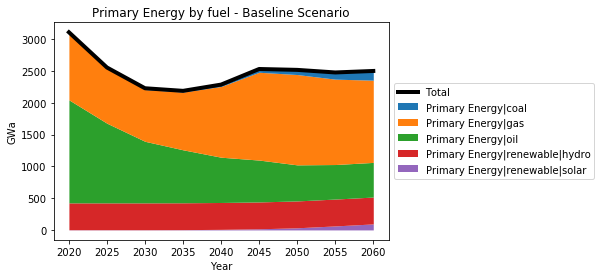

In [197]:
pdf.filter(scenario = 'baseline', variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs).stack_plot(total=True,
                                        title = 'Primary Energy by fuel - Baseline Scenario')

In [50]:
# gas = pyam_df.filter(scenario = 'baseline', variable=[
#                                             "Primary Energy|gas",
#                                             ],
#               year = plotyrs)

pyam.core - WARNING: Filtered IamDataFrame is empty!


In [51]:
gas.head(10)

,model,scenario,region,variable,unit,year,value


In [52]:
i_feed = ['Useful Energy|i_feed|ethanol_fs|M1', 'Useful Energy|i_feed|gas_fs|M1',
         'Useful Energy|i_feed|loil_fs|M1', 'Useful Energy|i_feed|methanol_fs|M1']

transport = ['Useful Energy|transport|coal_trp|M1',
            'Useful Energy|transport|elec_trp|M1',
            'Useful Energy|transport|eth_fc_trp|M1',
            'Useful Energy|transport|eth_ic_trp|M1',
            'Useful Energy|transport|foil_trp|M1',
            'Useful Energy|transport|gas_trp|M1',
            'Useful Energy|transport|h2_fc_trp|M1',
            'Useful Energy|transport|loil_trp|M1',
            'Useful Energy|transport|meth_fc_trp|M1',
            'Useful Energy|transport|meth_ic_trp|M1']


i_spec = ['Useful Energy|i_spec|h2_fc_I|M1',
          'Useful Energy|i_spec|sp_coal_I|M1',
          'Useful Energy|i_spec|sp_el_I|M1',
          'Useful Energy|i_spec|sp_eth_I|M1',
          'Useful Energy|i_spec|sp_liq_I|M1',
          'Useful Energy|i_spec|sp_meth_I|M1']

i_therm =   ['Useful Energy|i_therm|biomass_i|M1',
            'Useful Energy|i_therm|coal_i|M1',
            'Useful Energy|i_therm|elec_i|M1',
            'Useful Energy|i_therm|eth_i|M1',
            'Useful Energy|i_therm|foil_i|M1',
            'Useful Energy|i_therm|gas_i|M1',
            'Useful Energy|i_therm|h2_fc_I|M1',
            'Useful Energy|i_therm|h2_i|M1',
            'Useful Energy|i_therm|heat_i|M1',
            'Useful Energy|i_therm|hp_el_i|M1',
            'Useful Energy|i_therm|hp_gas_i|M1',
            'Useful Energy|i_therm|loil_i|M1',
            'Useful Energy|i_therm|meth_i|M1',
            'Useful Energy|i_therm|solar_i|M1']
rc_spec = ['Useful Energy|rc_spec|h2_fc_RC|M1',
          'Useful Energy|rc_spec|sp_el_RC|M1']

rc_therm = ['Useful Energy|rc_therm|biomass_rc|M1',
            'Useful Energy|rc_therm|coal_rc|M1',
            'Useful Energy|rc_therm|eth_rc|M1',
            'Useful Energy|rc_therm|foil_rc|M1',
            'Useful Energy|rc_therm|gas_rc|M1',
            'Useful Energy|rc_therm|h2_fc_RC|M1',
            'Useful Energy|rc_therm|h2_rc|M1',
            'Useful Energy|rc_therm|heat_rc|M1',
            'Useful Energy|rc_therm|hp_el_rc|M1',
            'Useful Energy|rc_therm|hp_gas_rc|M1',
            'Useful Energy|rc_therm|loil_rc|M1',
            'Useful Energy|rc_therm|meth_rc|M1',
            'Useful Energy|rc_therm|solar_rc|M1']

biom = ['Useful Energy|non-comm|biomass_nc|M1']

In [53]:
df_useful = pyam_df.copy()
# df_useful.aggregate(
#     "Useful Energy|non-Commercial biomass",
#     components=biom,
#     append=True
# )

df_useful.aggregate(
    "Useful Energy|residential/commercial thermal",
    components=rc_therm,
    append=True
)

df_useful.aggregate(
    "Useful Energy|residential/commercial specific",
    components=rc_spec,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial thermal",
    components=i_therm,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial specific",
    components=i_spec,
    append=True
)

df_useful.aggregate(
    "Useful Energy|industrial feedstock",
    components=i_feed,
    append=True
)

df_useful.aggregate(
    "Useful Energy|transport",
    components=i_therm,
    append=True
)


/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:10: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  # Remove the CWD from sys.path while we load stuff.


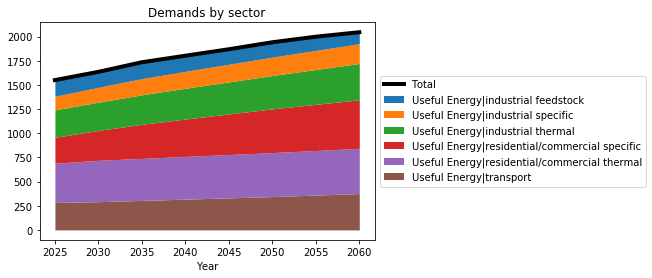

In [54]:
df_useful.filter(scenario = 'baseline', variable=[
    "Useful Energy|non-Commercial biomass",
    "Useful Energy|residential/commercial thermal",
    "Useful Energy|residential/commercial specific",
    "Useful Energy|industrial thermal",
    "Useful Energy|industrial specific",
    "Useful Energy|industrial feedstock",
    "Useful Energy|transport"],
              year = plotyrs).stack_plot(total=True,
                                         title = 'Demands by sector')

In [55]:
cement = ['Emissions|CO2|cement_CO2|M1']
coal = ['Emissions|CO2|coal_extr_ch4|M1',
        'Emissions|CO2|coal_extr|M1',
        'Emissions|CO2|coal_imp|M1']
foil = ['Emissions|CO2|foil_imp|M1']
gas = ['Emissions|CO2|gas_extr_1|M1',
        'Emissions|CO2|gas_extr_2|M1',
        'Emissions|CO2|gas_extr_3|M1',
        'Emissions|CO2|gas_extr_4|M1',
        'Emissions|CO2|gas_extr_5|M1',
        'Emissions|CO2|gas_extr_6|M1'
        ]
lignite = ['Emissions|CO2|lignite_extr|M1']
loil = ['Emissions|CO2|loil_imp|M1']
meth_ccs = ['Emissions|CO2|meth_coal_ccs|M1']
oil = ['Emissions|CO2|oil_extr_1_ch4|M1',
    'Emissions|CO2|oil_extr_1|M1',
    'Emissions|CO2|oil_extr_2_ch4|M1',
    'Emissions|CO2|oil_extr_2|M1',
    'Emissions|CO2|oil_extr_3_ch4|M1',
    'Emissions|CO2|oil_extr_3|M1',
    'Emissions|CO2|oil_extr_4_ch4|M1',
    'Emissions|CO2|oil_extr_4|M1',
    'Emissions|CO2|oil_extr_5|M1',
    'Emissions|CO2|oil_extr_6|M1',
    'Emissions|CO2|oil_extr_7|M1']

oil_trade = ['Emissions|CO2|foil_imp|M1',
             'Emissions|CO2|loil_exp|M1',
            'Emissions|CO2|loil_imp|M1',
             'Emissions|CO2|oil_imp|M1']
       
gas_trade = ['Emissions|CO2|LNG_exp|M1',
            'Emissions|CO2|LNG_imp|M1',
            'Emissions|CO2|gas_imp|M1']
            #'Emissions|CO2|LNG_exp|M1']

In [56]:
df_emis_b = pyam_df.filter(variable = 'Emissions|CO2|*',year = plotyrs)

In [57]:
df_emis_b.to_csv('emissions.csv')

In [58]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:9: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  if __name__ == '__main__':


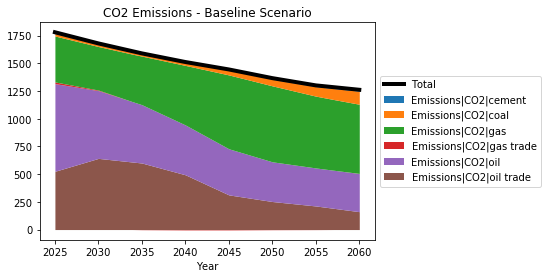

In [59]:
df_emis.filter(scenario = 'baseline', variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs).stack_plot(total=True,
                                         title = 'CO2 Emissions - Baseline Scenario')

In [127]:
df_emis.aggregate('Emissions|*').timeseries()

,,,,,1950,1955,1960,1965,1970,1975,1980,1985,1990,1995,...,2010,2015,2025,2030,2035,2040,2045,2050,2055,2060
model,scenario,region,variable,unit,,,,,,,,,,,,,,,,,,,,,
MESSAGEix_CA,baseline,Canada,Emissions|*,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,61020.496817,62311.944897,56621.055583,47632.991676,39756.453929,34141.832891,31221.520469,29296.783378


In [60]:

coal = ['Total Costs|coal_adv',
        'Total Costs|coal_adv_ccs',
        'Total Costs|coal_bal',
        'Total Costs|coal_exp',
        'Total Costs|coal_extr',
        'Total Costs|coal_extr_ch4',
        'Total Costs|coal_gas',
        'Total Costs|coal_hpl',
        'Total Costs|coal_i',
        'Total Costs|coal_imp',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
        'Total Costs|coal_rc',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
       'Total Costs|coal_t_d',
       'Total Costs|syn_liq',
        'Total Costs|meth_coal',
       'Total Costs|lignite_extr']
biomass = ['bio_hpl', 'bio_ppl',
          'Total Costs|liq_bio']


elec = ['Total Costs|elec_exp',
        'Total Costs|elec_i',
        'Total Costs|elec_imp',
        'Total Costs|elec_t_d',
        'Total Costs|elec_trp']

oil = ['Total Costs|foil_i',
    'Total Costs|foil_imp',
    'Total Costs|foil_ppl',
    'Total Costs|oil_extr_1'
    'Total Costs|oil_extr_1_ch4'
    'Total Costs|oil_extr_2',
    'Total Costs|oil_extr_3',
    'Total Costs|oil_extr_4',
    'Total Costs|oil_extr_5',
    'Total Costs|oil_extr_6',
    'Total Costs|oil_extr_7',
    'Total Costs|oil_extr_2_ch4',
    'Total Costs|oil_extr_3_ch4',
    'Total Costs|loil_cc',
    'Total Costs|loil_ppl']
gas = ['Total Costs|gas_bal',
    'Total Costs|gas_bio',
    'Total Costs|gas_cc',
    'Total Costs|gas_cc_ccs',
    'Total Costs|gas_ct',
    'Total Costs|gas_extr_1',
    'Total Costs|gas_extr_2',
    'Total Costs|gas_extr_3',
    'Total Costs|gas_extr_4',
    'Total Costs|gas_extr_5',
    'Total Costs|gas_extr_6',
    'Total Costs|gas_extr_mpen',
    'Total Costs|gas_fs',
    'Total Costs|gas_hpl',
    'Total Costs|gas_i',
    'Total Costs|gas_imp',
    'Total Costs|gas_ppl',
    'Total Costs|gas_rc',
    'Total Costs|gas_t_d',
    'Total Costs|gas_t_d_ch4',
    'Total Costs|gas_trp',
      'Total Costs|igcc']

geo_ppl = ['Total Costs|geo_hpl','Total Costs|geo_ppl']

solar = ['Total Costs|solar_i',
        'Total Costs|solar_pv_ppl',
        'Total Costs|solar_rc',
        'Total Costs|solar_th_ppl']

wind = ['Total Costs|wind_curtailment1',
'Total Costs|wind_curtailment2',
'Total Costs|wind_curtailment3',
'Total Costs|wind_ppf',
'Total Costs|wind_ppl']

hydro = ['Total Costs|hydro_hc',
'Total Costs|hydro_lc']

nuclear = ['Total Costs|nuc_lc']


In [61]:
df_cost = pyam_df.copy()


df_cost.aggregate(
    "Total Costs|coal",
    components=coal,
    append=True
)

df_cost.aggregate(
    "Total Costs|biomass",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|electricity",
    components=elec,
    append=True
)

df_cost.aggregate(
    "Total Costs|oil",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|gas",
    components=gas,
    append=True
)

df_cost.aggregate(
    "Total Costs|geothermal",
    components=geo_ppl,
    append=True
)

df_cost.aggregate(
    "Total Costs|solar",
    components=solar,
    append=True
)

df_cost.aggregate(
    "Total Costs|wind",
    components=wind,
    append=True
)

df_cost.aggregate(
    "Total Costs|hydro",
    components=hydro,
    append=True
)
df_cost.aggregate(
    "Total Costs|nuclear",
    components=nuclear,
    append=True
)

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:12: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  if sys.path[0] == '':


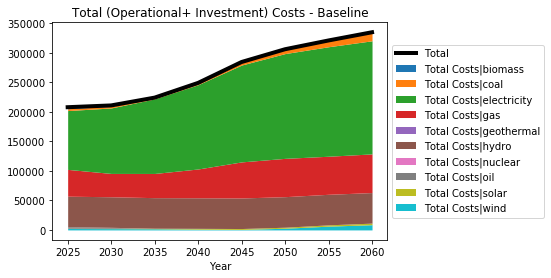

In [62]:
df_cost.filter(scenario = 'baseline', variable=
    ["Total Costs|coal","Total Costs|biomass",
    "Total Costs|electricity",
    "Total Costs|oil",
    "Total Costs|gas",
    "Total Costs|geothermal",
    "Total Costs|solar",
    "Total Costs|wind",
    "Total Costs|hydro",
    "Total Costs|nuclear"],
              year = plotyrs).stack_plot(total=True,
                                         title = 'Total (Operational+ Investment) Costs - Baseline')


Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 


In [204]:
msgbas = msg.clone(modelName, 'Baseline-NDC','Introducing Canadas goals',
                     keep_solution=False)

In [205]:
msgbas.check_out()

In [ ]:
msg.par('emiss')

In [206]:

def expand_grid(dictionary):
    return pd.DataFrame([row for row in product(*dictionary.values())], 
                       columns=dictionary.keys())


In [222]:
  
    
year_df = [2020, 2025, 2030, 2035, 2040 ,2045 ,2050 ,2055 ,2060 ]


dic = {
    'node': [nodeName],
    'type_emission':[str('TCE')],
    'type_tec':[str('all')],
    'type_year': [2020, 2025, 2030, 2035, 2040 ,2045 ,2050 ,2055 ,2060 ],
    'value':     [629, 572, 526, 450 , 375, 320, 255, 200, 150],
    'unit':[str('-')]}

df = expand_grid(dic)
df = df.iloc[0:9]
df['type_year'] = year_df



In [224]:
# msgbas.remove_solution()

In [225]:
msgbas.check_out()

In [226]:
#msgSDG.add_par('bound_emission',df)
msgbas.add_par('bound_emission', df)
msgbas.commit('emissions bounded ')

In [227]:
msgbas.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

In [229]:
from message_ix.reporting import Reporter
from update_units import unit_correction
import numpy as np
unit_correct = False  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060

if unit_correct:
    msg = msg.clone(keep_solution=False)
    unit_correction(mp, msg)
    caseName = msg.model + '__' + msg.scenario + '__v' + str(msg.version)
    # Solving the model
    msg.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

#%% Generating reporter
rep = Reporter.from_scenario(msgbas)
report = rep.get('message:default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()

    # Plotted years
years = msgbas.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
c = report_df.select_dtypes(include=[np.number]) * 8.76
report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = out_flows.append(in_flows)

emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
ixmp.reporting.computations - WARNING: emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded


In [230]:
report_df.to_csv('MESSAGE_CANADA_baselinendc.csv')

In [233]:
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
#report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('emis', 'Emissions', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
# report_df1["Variable"] = report_df1["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)

In [234]:
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
pdf = pyam_df.copy()

In [235]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!
pyam.utils - WARNING: Formatted data is empty!


In [238]:
pdf.filter(variable = 'Primary Energy|oil').timeseries()

,,,,,1950,1955,1960,1965,1970,1975,1980,1985,1990,1995,...,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
model,scenario,region,variable,unit,,,,,,,,,,,,,,,,,,,,,
CD_Links_SSP2_R14,Baseline-NDC,Canada|Canada,Primary Energy|oil,GWa,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1621.491237,1253.490002,968.737662,823.460493,679.226535,629.460614,535.074629,492.654937,471.455072


/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:15: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  from ipykernel import kernelapp as app


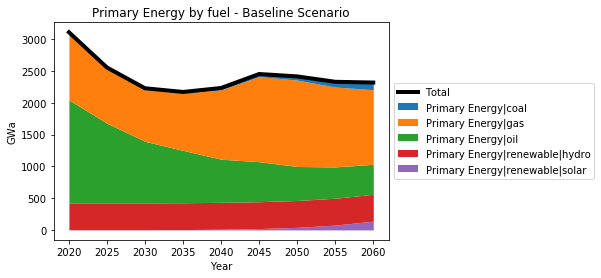

In [239]:
pdf.filter( variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs).stack_plot(total=True,
                                        title = 'Primary Energy by fuel - Baseline Scenario')

In [240]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

In [242]:
df_emis.timeseries()

1950  \
model             scenario     region       variable                       unit         
CD_Links_SSP2_R14 Baseline-NDC Canada       Emissions|BCA|bio_hpl|M1              0.0   
                                            Emissions|BCA|bio_istig_ccs|M1        0.0   
                                            Emissions|BCA|bio_istig|M1            0.0   
                                            Emissions|BCA|bio_ppl|M1              0.0   
                                            Emissions|BCA|biomass_i|M1            0.0   
...                                                                               ...   
                               Canada|World out|stocks|puq|nuc_lc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_hc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_lc|M1       GWa    0.0   
                                            out|stocks|uq|nuc_hc|M1        GWa    0.0   
                                            out|stocks|uq|nuc_lc|M1        GWa    0.0   

                                                                                 1955  \
model             scenario     region       variable                       unit         
CD_Links_SSP2_R14 Baseline-NDC Canada       Emissions|BCA|bio_hpl|M1              0.0   
                                            Emissions|BCA|bio_istig_ccs|M1        0.0   
                                            Emissions|BCA|bio_istig|M1            0.0   
                                            Emissions|BCA|bio_ppl|M1              0.0   
                                            Emissions|BCA|biomass_i|M1            0.0   
...                                                                               ...   
                               Canada|World out|stocks|puq|nuc_lc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_hc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_lc|M1       GWa    0.0   
                                            out|stocks|uq|nuc_hc|M1        GWa    0.0   
                                            out|stocks|uq|nuc_lc|M1        GWa    0.0   

                                                                                 1960  \
model             scenario     region       variable                       unit         
CD_Links_SSP2_R14 Baseline-NDC Canada       Emissions|BCA|bio_hpl|M1              0.0   
                                            Emissions|BCA|bio_istig_ccs|M1        0.0   
                                            Emissions|BCA|bio_istig|M1            0.0   
                                            Emissions|BCA|bio_ppl|M1              0.0   
                                            Emissions|BCA|biomass_i|M1            0.0   
...                                                                               ...   
                               Canada|World out|stocks|puq|nuc_lc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_hc|M1       GWa    0.0   
                                            out|stocks|u5q|nuc_lc|M1       GWa    0.0   
                                            out|stocks|uq|nuc_hc|M1        GWa    0.0   
                                            out|stocks|uq|nuc_lc|M1        GWa    0.0   

                                                                                 1965  \
model             scenario     region       variable                       unit         
CD_Links_SSP2_R14 Baseline-NDC Canada       Emissions|BCA|bio_hpl|M1              0.0   
                                            Emissions|BCA|bio_istig_ccs|M1        0.0   
                                            Emissions|BCA|bio_istig|M1            0.0   
                                            Emissions|BCA|bio_ppl|M1              0.0   
                                            Emissions|BCA|biomass_i|M1   

/Users/MuhammadAwais/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:9: DeprecationWarning: This method is deprecated and will be removed in future versions. Please use `IamDataFrame.plot.stack()`.
  if __name__ == '__main__':


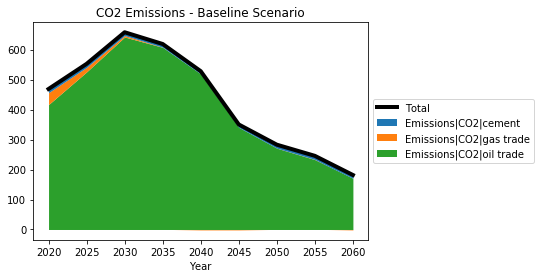

In [243]:
df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs,region = 'Canada').stack_plot(total=True,
                                         title = 'CO2 Emissions - Baseline Scenario')

In [3]:
import pandas as pd

In [5]:
df = pd.read_csv('MESSAGE_CANADA_baselinendc.csv')

In [8]:
df['Model'].replace('CD_Links_SSP2_R14', 'MESSAGEix-Canada', inplace=True)

In [9]:
df.head()

,Unnamed: 0,Model,Scenario,Region,Variable,Unit,1950,1955,1960,1965,...,2015,2020,2025,2030,2035,2040,2045,2050,2055,2060
0,0,MESSAGEix-Canada,Baseline-NDC,Canada,capacity|LNG_exp,NaN,0.0,0.0,0.0,0.0,...,0.0,0.000000,2.962856,2.962856,2.962856,2.962856,2.962856,0.000000,0.000000,2.962856
1,1,MESSAGEix-Canada,Baseline-NDC,Canada,capacity|adipic_thermal,NaN,0.0,0.0,0.0,0.0,...,0.0,0.000963,0.002513,0.005010,0.009031,0.015507,0.025937,0.036125,0.047558,0.049841
2,2,MESSAGEix-Canada,Baseline-NDC,Canada,capacity|ammonia_secloop,NaN,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.292965
3,3,MESSAGEix-Canada,Baseline-NDC,Canada,capacity|bio_hpl,NaN,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,4,MESSAGEix-Canada,Baseline-NDC,Canada,capacity|bio_hpl__air,NaN,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [10]:
df.to_csv('MESSAGE_CANADA_v1.csv')

In [2]:
import pandas as pd

In [3]:
iso = 'CAN'

In [37]:
# SSP GDP data
ssp_gdp_df = pd.read_excel( str('OECD_SSP_GDP_PPP.xlsx'),
        'OECD_SSP_GDP_PPP',
        header = 0)
ssp_gdp_df = ssp_gdp_df.loc[ (  ssp_gdp_df.Region == iso ) ].reset_index(drop=True)

# SSP population data

ssp_pop_df = pd.read_excel(str('OECD_SSP_POP.xlsx'),
        'OECD_SSP_POP',
        header = 0)
ssp_pop_df = ssp_pop_df.loc[ (  ssp_pop_df.Region == iso  ) ].reset_index(drop=True)

In [41]:
ssp_pop_df['Scenario'] = ssp_pop_df['Scenario'].str.replace('_v9_130325', '')
ssp_gdp_df['Scenario'] = ssp_gdp_df['Scenario'].str.replace('_v9_130325', '')

In [42]:
ssp_gdp_df

,Model,Scenario,Region,UN_Code,Country_Name,Status,Eleven_region,Variable,Unit,2000,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
0,OECD Env-Growth,SSP1,CAN,124.0,Canada,IND,NAM,GDP|PPP,billion US$2005/yr,998.233,...,2907.507,3156.571,3432.186,3722.703,4012.466,4300.718,4573.909,4831.523,5078.940,5318.188
1,OECD Env-Growth,SSP2,CAN,124.0,Canada,IND,NAM,GDP|PPP,billion US$2005/yr,998.233,...,2848.396,3067.688,3311.851,3575.443,3846.626,4123.553,4399.106,4674.884,4953.774,5236.013
2,OECD Env-Growth,SSP3,CAN,124.0,Canada,IND,NAM,GDP|PPP,billion US$2005/yr,998.233,...,2376.839,2464.637,2548.178,2620.583,2673.917,2713.571,2739.622,2758.571,2775.279,2785.509
3,OECD Env-Growth,SSP4,CAN,124.0,Canada,IND,NAM,GDP|PPP,billion US$2005/yr,998.233,...,2870.101,3079.408,3306.594,3540.534,3764.788,3981.931,4183.021,4370.384,4544.905,4698.999
4,OECD Env-Growth,SSP5,CAN,124.0,Canada,IND,NAM,GDP|PPP,billion US$2005/yr,998.233,...,4837.187,5563.307,6382.766,7299.905,8305.914,9393.260,10547.885,11771.509,13079.525,14493.948


In [43]:
import pyam
import matplotlib.pyplot as plt
import pyam

pop_df = pyam.IamDataFrame(ssp_pop_df)
gdp_df = pyam.IamDataFrame(ssp_gdp_df)

In [44]:
pop_df.head()

,model,scenario,region,variable,unit,year,eleven_region,un_code,country_name,status,value
0,OECD Env-Growth,SSP1,CAN,Population,million,2000,NAM,124.0,Canada,IND,30.667
1,OECD Env-Growth,SSP1,CAN,Population,million,2005,NAM,124.0,Canada,IND,32.283
2,OECD Env-Growth,SSP1,CAN,Population,million,2010,NAM,124.0,Canada,IND,34.017
3,OECD Env-Growth,SSP1,CAN,Population,million,2015,NAM,124.0,Canada,IND,35.901
4,OECD Env-Growth,SSP1,CAN,Population,million,2020,NAM,124.0,Canada,IND,37.898


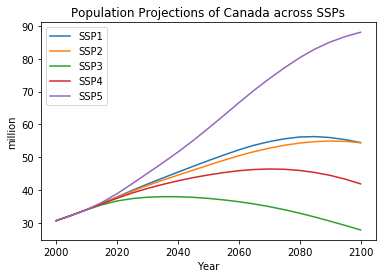

In [45]:
pop_df.plot(color='scenario', title='Population Projections of Canada across SSPs')

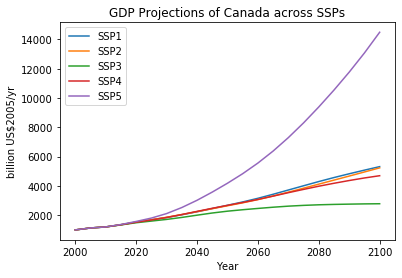

In [46]:
gdp_df.plot(color='scenario', title='GDP Projections of Canada across SSPs')